# 04 · Modelos paramétricos AFT / Accelerated failure time models

$$\log T = \beta^\top x + \sigma\,\varepsilon$$

Em vez de multiplicar o *risco*, as covariáveis **aceleram ou desaceleram o tempo**:
$\exp(\beta_j)$ é um **time ratio**; TR = 1,2 significa permanência 20% **maior**.
Vantagem: não assume riscos proporcionais e permite extrapolar a curva.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


In [2]:
from lifelines import WeibullFitter, LogNormalFitter, LogLogisticFitter, ExponentialFitter
from lifelines.plotting import qq_plot

X = data.make_design_matrix(df)
train, test = data.split(X)

## Qual distribuição? / Which distribution? (univariate)

,distribution,AIC
3,LogLogistic,5926.850
2,LogNormal,5926.986
1,Weibull,5927.470
0,Exponential,5929.483


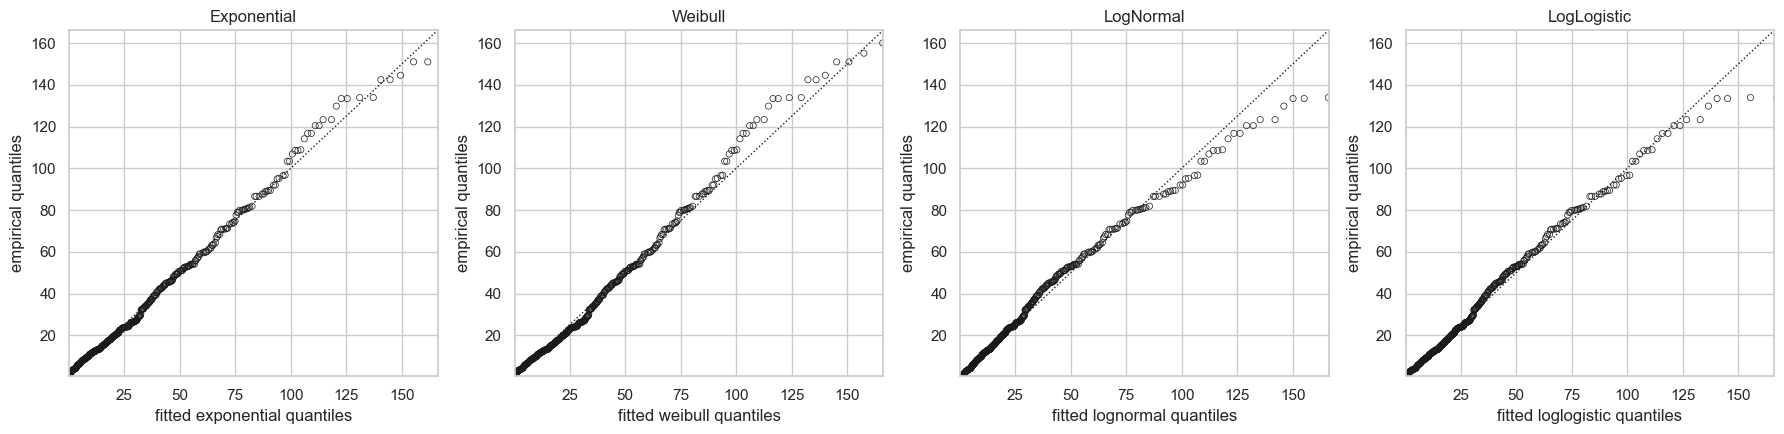

In [3]:
fitters = [ExponentialFitter(), WeibullFitter(), LogNormalFitter(), LogLogisticFitter()]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
rows = []
for f, ax in zip(fitters, axes):
    f.fit(df[T], df[E])
    qq_plot(f, ax=ax)
    ax.set_title(f.__class__.__name__.replace("Fitter", ""))
    rows.append({"distribution": f.__class__.__name__.replace("Fitter", ""), "AIC": f.AIC_})
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "04_qq.png", dpi=120, bbox_inches="tight")
pd.DataFrame(rows).sort_values("AIC")

Pontos sobre a diagonal no QQ-plot indicam bom ajuste da distribuição.

## AFT com covariáveis / AFT regression

In [4]:
aft = models.fit_aft_models(train)
models.compare_aft(aft)

,model,AIC,log_likelihood,concordance_train
0,Weibull,4403.254,-2158.627,0.656
1,LogLogistic,4421.454,-2167.727,0.665
2,LogNormal,4437.826,-2175.913,0.666


In [5]:
best_name = models.compare_aft(aft).iloc[0]["model"]
best = aft[best_name]
print("Best by AIC:", best_name)

s = best.summary.loc[best.summary.index.get_level_values(0).str.contains("lambda_|mu_|alpha_", regex=True)]
s = s.reset_index().query("covariate != 'Intercept'")
s["time_ratio"] = np.exp(s["coef"])
s[["covariate", "time_ratio", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].sort_values("time_ratio")

Best by AIC: Weibull


,covariate,time_ratio,exp(coef) lower 95%,exp(coef) upper 95%,p
27,profession_manage,0.408,0.240,0.694,0.001
9,industry_banks,0.479,0.357,0.644,0.000
10,industry_building,0.553,0.370,0.827,0.004
11,industry_consult,0.553,0.390,0.786,0.001
28,profession_marketing,0.561,0.361,0.872,0.010
18,industry_state,0.579,0.378,0.889,0.012
23,profession_commercial,0.580,0.348,0.967,0.037
25,profession_etc,0.584,0.362,0.943,0.028
24,profession_consult,0.598,0.342,1.045,0.071
12,industry_etc,0.614,0.443,0.852,0.003


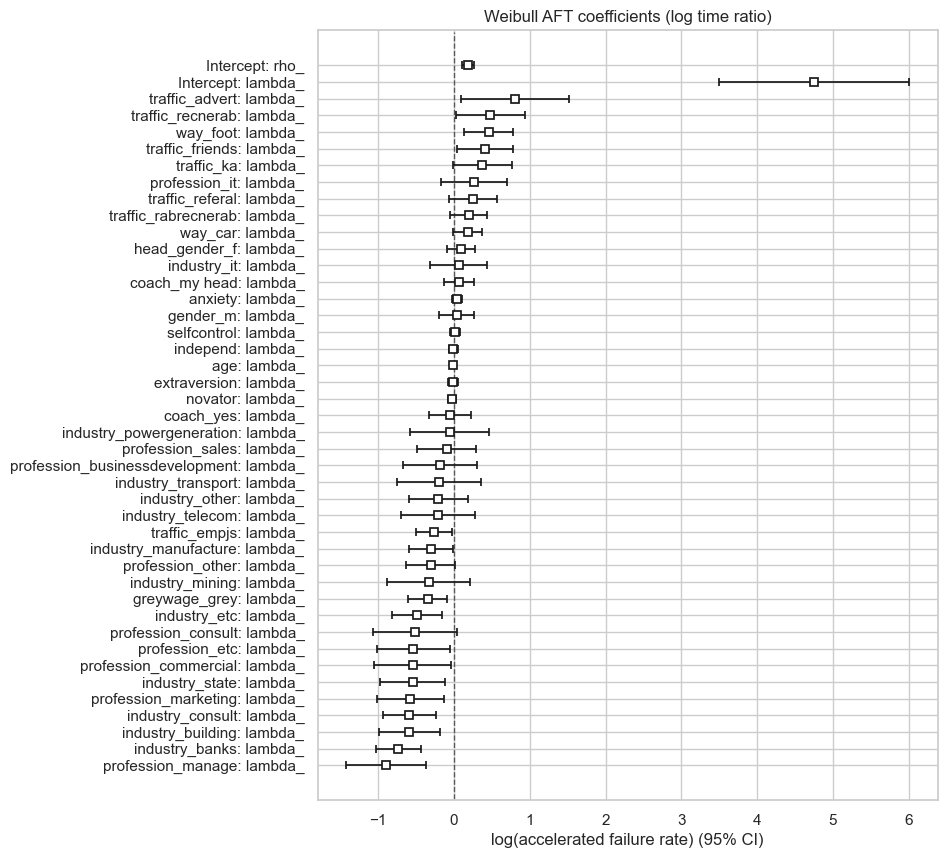

In [6]:
fig, ax = plt.subplots(figsize=(8, 10))
best.plot(ax=ax)
ax.set_title(f"{best_name} AFT coefficients (log time ratio)")
fig.savefig(config.FIGURES_DIR / "04_aft_coefs.png", dpi=120, bbox_inches="tight")

**Leitura:** time ratio < 1 → a característica **encurta** o tempo até a saída (maior risco);
> 1 → **alonga** a permanência.

## Mediana prevista no teste / Predicted median tenure

In [7]:
pred = best.predict_median(models.features(test)).rename("predicted_median_months")
pd.concat([test[[T, E]], pred], axis=1).head(10)

,stag,event,predicted_median_months
289,73.823,0,39.060
645,144.756,0,70.280
540,23.458,0,68.989
790,24.838,0,91.729
507,129.281,0,50.231
147,5.651,1,67.933
124,38.768,1,73.334
299,23.984,1,42.089
176,16.000,1,87.662
382,49.281,0,64.255


### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._